:::{danger} Ejercicio sin validar: no usar para tomar decisiones
Este cuaderno **no ha sido validado por una persona experta** en modelación de tsunamis. Es un ejercicio de reproducibilidad y de aprendizaje. Sus resultados **no deben usarse para tomar decisiones** de gestión del riesgo, ordenamiento territorial, diseño de obras, planes de evacuación ni alertas.

Falta, como mínimo: la revisión por una persona experta; la distribución de deslizamiento real del evento (la geometría de la falla es un supuesto); la validación contra observaciones de 1979 que se contradicen entre fuentes (véase el cuaderno 3); y un modelo no lineal con cálculo de inundación.
:::

# Cuaderno 3: Visualización y comparación con 1979

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/scr-ungrd/cuadernos-reproducibles-crc002/blob/main/notebooks/03-visualization.ipynb)

Mapas, series de tiempo, control de calidad de las observaciones, comparación con 1979 y animación. **Requiere los resultados del cuaderno 2**
(`output/resultados.npz`). **Runtime:** CPU, 1–2 minutos.

**Qué es y qué no es la comparación.** Las observaciones de `data/observaciones_1979.csv` se reconstruyeron en la versión 2.2 con su procedencia: cada valor
dice si viene de Herd et al. (1981) o de la base de run-ups de NOAA/NGDC, y **las dos fuentes no coinciden** (Tumaco: 0,8 m frente a 3 m; San Juan de la Costa: 2,5 m frente a 6 m).
Por eso no se compara contra un número sino contra el **rango** entre fuentes. El modelo es lineal y sin inundación, de modo que su η en el mar **no es un run-up**.
Solo hay dos tiempos de arribo documentados (Buenaventura y Esmeraldas), así que la comparación de tiempos es mínima. Se muestran diferencias para ubicar el orden de
magnitud y los límites del modelo, no para validarlo.

In [1]:
import sys, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio', 'pyproj'], check=True)
import rasterio
from rasterio.crs import CRS
from pyproj import Transformer

WORK = Path('/content') if IN_COLAB else Path('.')
OUT = WORK / 'output'
OUT.mkdir(exist_ok=True)
RAW = 'https://raw.githubusercontent.com/scr-ungrd/cuadernos-reproducibles-crc002/main/data/'

def datos(nombre):
    """Ruta de un archivo de data/: local (../data) o descargado del repositorio (Colab)."""
    for base in (Path('../data'), Path('data'), WORK / 'data'):
        if (base / nombre).exists():
            return base / nombre
    import requests
    destino = WORK / 'data'
    destino.mkdir(exist_ok=True)
    r = requests.get(RAW + nombre, timeout=120)
    r.raise_for_status()
    (destino / nombre).write_bytes(r.content)
    return destino / nombre

# Epicentro del 12-dic-1979 (1,584° N, 79,386° O: tabla 1 de Herd et al., 1981, hipocentro del NEIS)
EPI = (-79.386, 1.584)                       # (lon, lat)
CRS_UTM = CRS.from_epsg(32617)               # UTM 17N, meridiano central 81° O (error de escala < 0,2 % en el dominio)
TR = Transformer.from_crs(4326, 32617, always_xy=True)
G = 9.81

def ejes_lonlat(ax, paso=1):
    """Marcas de longitud y latitud sobre un mapa en coordenadas UTM (km); oeste a la izquierda, norte arriba."""
    lons = np.arange(-81, -76.5, paso); lats = np.arange(0, 4.5, paso)
    xl, yl = ax.get_xlim(), ax.get_ylim()
    ax.set_xticks([TR.transform(l, 2.0)[0] / 1e3 for l in lons]); ax.set_xticklabels([f'{abs(l):g}°O' for l in lons])
    ax.set_yticks([TR.transform(-79.0, l)[1] / 1e3 for l in lats]); ax.set_yticklabels([f'{l:g}°N' for l in lats])
    ax.set_xlim(xl); ax.set_ylim(yl)
    ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')

In [2]:
from matplotlib.animation import FuncAnimation, PillowWriter
if not (OUT / 'resultados.npz').exists():
    raise FileNotFoundError('Falta output/resultados.npz: ejecute primero el cuaderno 2.')
R = np.load(OUT / 'resultados.npz')
H = R['H'].astype('float64'); maxeta, tarr = R['maxeta'], R['tarr']
snap_t, snaps, rec, dt = R['snap_t'], R['snaps'], R['rec'], float(R['dt'])
x0, y0, dx = float(R['x0']), float(R['y0']), float(R['dx'])
ny, nx = H.shape
ext = [x0 / 1e3, (x0 + dx * nx) / 1e3, (y0 - dx * ny) / 1e3, y0 / 1e3]   # oeste a la izquierda, norte arriba
est = pd.read_csv(OUT / 'estaciones.csv'); obs = pd.read_csv(datos('observaciones_1979.csv'))
ex, ey = TR.transform(*EPI)
tt = np.arange(rec.shape[0]) * dt
print(f'Resultados: malla {nx}×{ny}, {len(snap_t)} instantáneas (0–{snap_t[-1]/60:.0f} min), {rec.shape[1]} estaciones en el mar')

# Prueba de orientación y de fuente: el máximo de η inicial debe estar cerca del epicentro (decenas de km), no a cientos
eta_ini = snaps[0].astype('float64')
i, j = np.unravel_index(np.argmax(eta_ini), eta_ini.shape)
d_max = np.hypot(x0 + dx * (j + .5) - ex, y0 - dx * (i + .5) - ey) / 1e3
assert d_max < 150, f'la fuente está a {d_max:.0f} km del epicentro'
print(f'✓ El máximo de η inicial ({eta_ini.max():.1f} m) está a {d_max:.0f} km del epicentro')

Resultados: malla 1065×1084, 28 instantáneas (0–108 min), 7 estaciones en el mar
✓ El máximo de η inicial (3.1 m) está a 75 km del epicentro


## 1. Control de calidad de las observaciones

Cada valor del CSV trae su procedencia: `runup_herd_m` (Herd et al., 1981, p. 442: altura **sobre la posición previa de la marea alta**) y `runup_noaa_m`
(base de run-ups de NOAA/NGDC, registro `id_noaa`; no se conoce la referencia vertical de cada registro). **No se promedian ni se mezclan**: donde hay dos valores se
trabaja con el rango. Solo dos estaciones tienen tiempo de arribo (`t_obs_min`) y su tipo difiere: **Buenaventura** es la primera ola *positiva* en el mareógrafo y
**Esmeraldas** es el inicio del *retroceso* del mar.

Para la primera ola positiva se revisa la coherencia con una onda larga $c=\sqrt{gH}$: con la distancia de círculo máximo $d$ al epicentro y el arribo $t$,
la profundidad equivalente es $H_{eq}=(d/t)^2/g$. Una ruta que cruza plataforma y talud da un valor medio bajo; un valor mayor que la profundidad del océano (~4 000 m) sería sospechoso.

In [3]:
def dist_km(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos puntos (grados) por la fórmula de haversine, con radio terrestre de 6 371 km."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

qc = obs.copy()
qc['runup_min_m'] = qc[['runup_herd_m', 'runup_noaa_m']].min(axis=1)
qc['runup_max_m'] = qc[['runup_herd_m', 'runup_noaa_m']].max(axis=1)
qc['dist_km'] = dist_km(EPI[1], EPI[0], qc.lat, qc.lon).round(0)
primera = qc.t_obs_tipo == 'primera_ola_positiva'
qc['H_equiv_m'] = np.where(primera, ((qc.dist_km * 1e3 / (qc.t_obs_min * 60)) ** 2 / G).round(-1), np.nan)
qc['sospechoso'] = np.where(qc.H_equiv_m > 4000, 'H equiv. > 4 000 m', '')
qc = qc.merge(est[['estacion', 'estado']], on='estacion')
dominio = (qc.lon.between(-81.2, -76.9)) & (qc.lat.between(-0.2, 4.2))
qc.loc[~dominio, 'estado'] = 'fuera del dominio'
conflicto = (qc.runup_herd_m.notna() & qc.runup_noaa_m.notna())
print(f'Estaciones con las dos fuentes: {int(conflicto.sum())}; en todas difieren por un factor de {(qc.runup_max_m / qc.runup_min_m)[conflicto].min():.1f} a {(qc.runup_max_m / qc.runup_min_m)[conflicto].max():.1f}')
qc[['estacion', 'dist_km', 'runup_herd_m', 'runup_noaa_m', 't_obs_min', 't_obs_tipo', 'H_equiv_m', 'sospechoso', 'estado']]

Estaciones con las dos fuentes: 2; en todas difieren por un factor de 2.4 a 3.8


,estacion,dist_km,runup_herd_m,runup_noaa_m,t_obs_min,t_obs_tipo,H_equiv_m,sospechoso,estado
0,Tumaco,78.0,0.8,3.00,NaN,NaN,NaN,,ok
1,San Juan de la Costa,121.0,2.5,6.00,NaN,NaN,NaN,,ok
2,Buenaventura,364.0,NaN,0.14,99.0,primera_ola_positiva,380.0,,ok
3,Esmeraldas,73.0,NaN,NaN,5.5,retroceso,NaN,,ok
4,Isla Gorgona,204.0,NaN,5.00,NaN,NaN,NaN,,ok
5,Guapi,200.0,NaN,2.00,NaN,NaN,NaN,,ok
6,Limones,210.0,NaN,2.00,NaN,NaN,NaN,,"sin mar de ≥ 10 m a < 10 km (el más cercano, a..."
7,Iscuandé,184.0,NaN,2.00,NaN,NaN,NaN,,"sin mar de ≥ 10 m a < 10 km (el más cercano, a..."
8,El Charco,229.0,NaN,2.00,NaN,NaN,NaN,,"sin mar de ≥ 10 m a < 10 km (el más cercano, a..."
9,Vuelta Larga,203.0,NaN,3.00,NaN,NaN,NaN,,ok


## 2. Elevación máxima de la ola

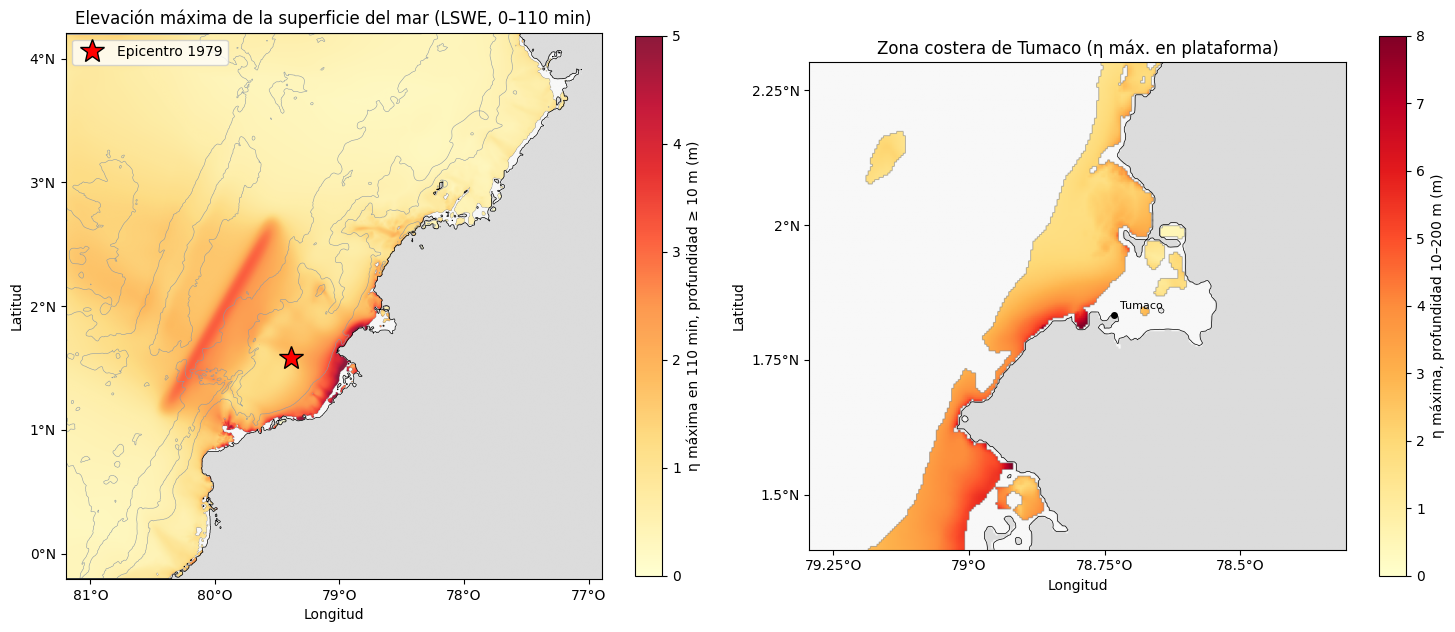

η máxima (profundidad ≥ 10 m): 8.80 m | plataforma 10–200 m: 8.80 m
(en celdas de < 10 m el modelo lineal llega a 40 m: amplificación sin fricción ni rotura, no se interpreta)


In [4]:
def fondo(ax):
    """Dibuja el fondo del mapa: tierra en gris claro y mar en gris más oscuro."""
    ax.imshow(np.where(H > 0, 0.97, 0.86), cmap='gray', vmin=0, vmax=1, extent=ext)
def costa(ax):
    """Dibuja la línea de costa (contorno de profundidad 0,5 m)."""
    ax.contour(np.linspace(ext[0], ext[1], nx), np.linspace(ext[3], ext[2], ny), H, levels=[0.5], colors='k', linewidths=.5)

fig, axs = plt.subplots(1, 2, figsize=(15, 7.5))
ax = axs[0]; fondo(ax)
ax.contour(np.linspace(ext[0], ext[1], nx), np.linspace(ext[3], ext[2], ny), H, levels=[200, 1000, 3000], colors='#8c99a6', linewidths=.4)
im = ax.imshow(np.where(H >= 10, np.maximum(maxeta, 0), np.nan), cmap='YlOrRd', vmin=0, vmax=5, extent=ext, alpha=.9)
costa(ax); plt.colorbar(im, ax=ax, shrink=.75, label='η máxima en 110 min, profundidad ≥ 10 m (m)')
ax.plot(ex / 1e3, ey / 1e3, '*', c='red', mec='k', ms=18, label='Epicentro 1979'); ax.legend(loc='upper left'); ejes_lonlat(ax)
ax.set_title('Elevación máxima de la superficie del mar (LSWE, 0–110 min)')

ax = axs[1]; fondo(ax)
zona = (H >= 10) & (H < 200)
im2 = ax.imshow(np.where(zona, np.maximum(maxeta, 0), np.nan), cmap='YlOrRd', vmin=0, vmax=8, extent=ext)
costa(ax); plt.colorbar(im2, ax=ax, shrink=.75, label='η máxima, profundidad 10–200 m (m)')
tx, ty = TR.transform(-78.80, 1.85)
ax.set_xlim(tx / 1e3 - 55, tx / 1e3 + 55); ax.set_ylim(ty / 1e3 - 50, ty / 1e3 + 50)
for _, r in qc.iterrows():
    x, y = TR.transform(r.lon, r.lat)
    if abs(x - tx) < 55e3 and abs(y - ty) < 50e3:
        ax.plot(x / 1e3, y / 1e3, 'ko', ms=4); ax.annotate(r.estacion, (x / 1e3, y / 1e3), textcoords='offset points', xytext=(4, 4), fontsize=8)
ejes_lonlat(ax, paso=.25); ax.set_title('Zona costera de Tumaco (η máx. en plataforma)')
plt.tight_layout(); plt.savefig(WORK / 'max_eta_map.png', dpi=130, bbox_inches='tight'); plt.show()
print(f'η máxima (profundidad ≥ 10 m): {maxeta[H>=10].max():.2f} m | plataforma 10–200 m: {maxeta[zona].max():.2f} m')
print(f'(en celdas de < 10 m el modelo lineal llega a {maxeta[H>0].max():.0f} m: amplificación sin fricción ni rotura, no se interpreta)')

## 3. Series de tiempo y arribos

Dos tiempos simulados por estación, leídos en la celda de mar descrita en el cuaderno 2: el **primer ascenso** (primer instante con η > 0,1 m) y el **primer descenso**
(primer instante con η < −0,1 m). El primero se compara con la primera ola positiva de Buenaventura; el segundo, con el inicio del retroceso en Esmeraldas.

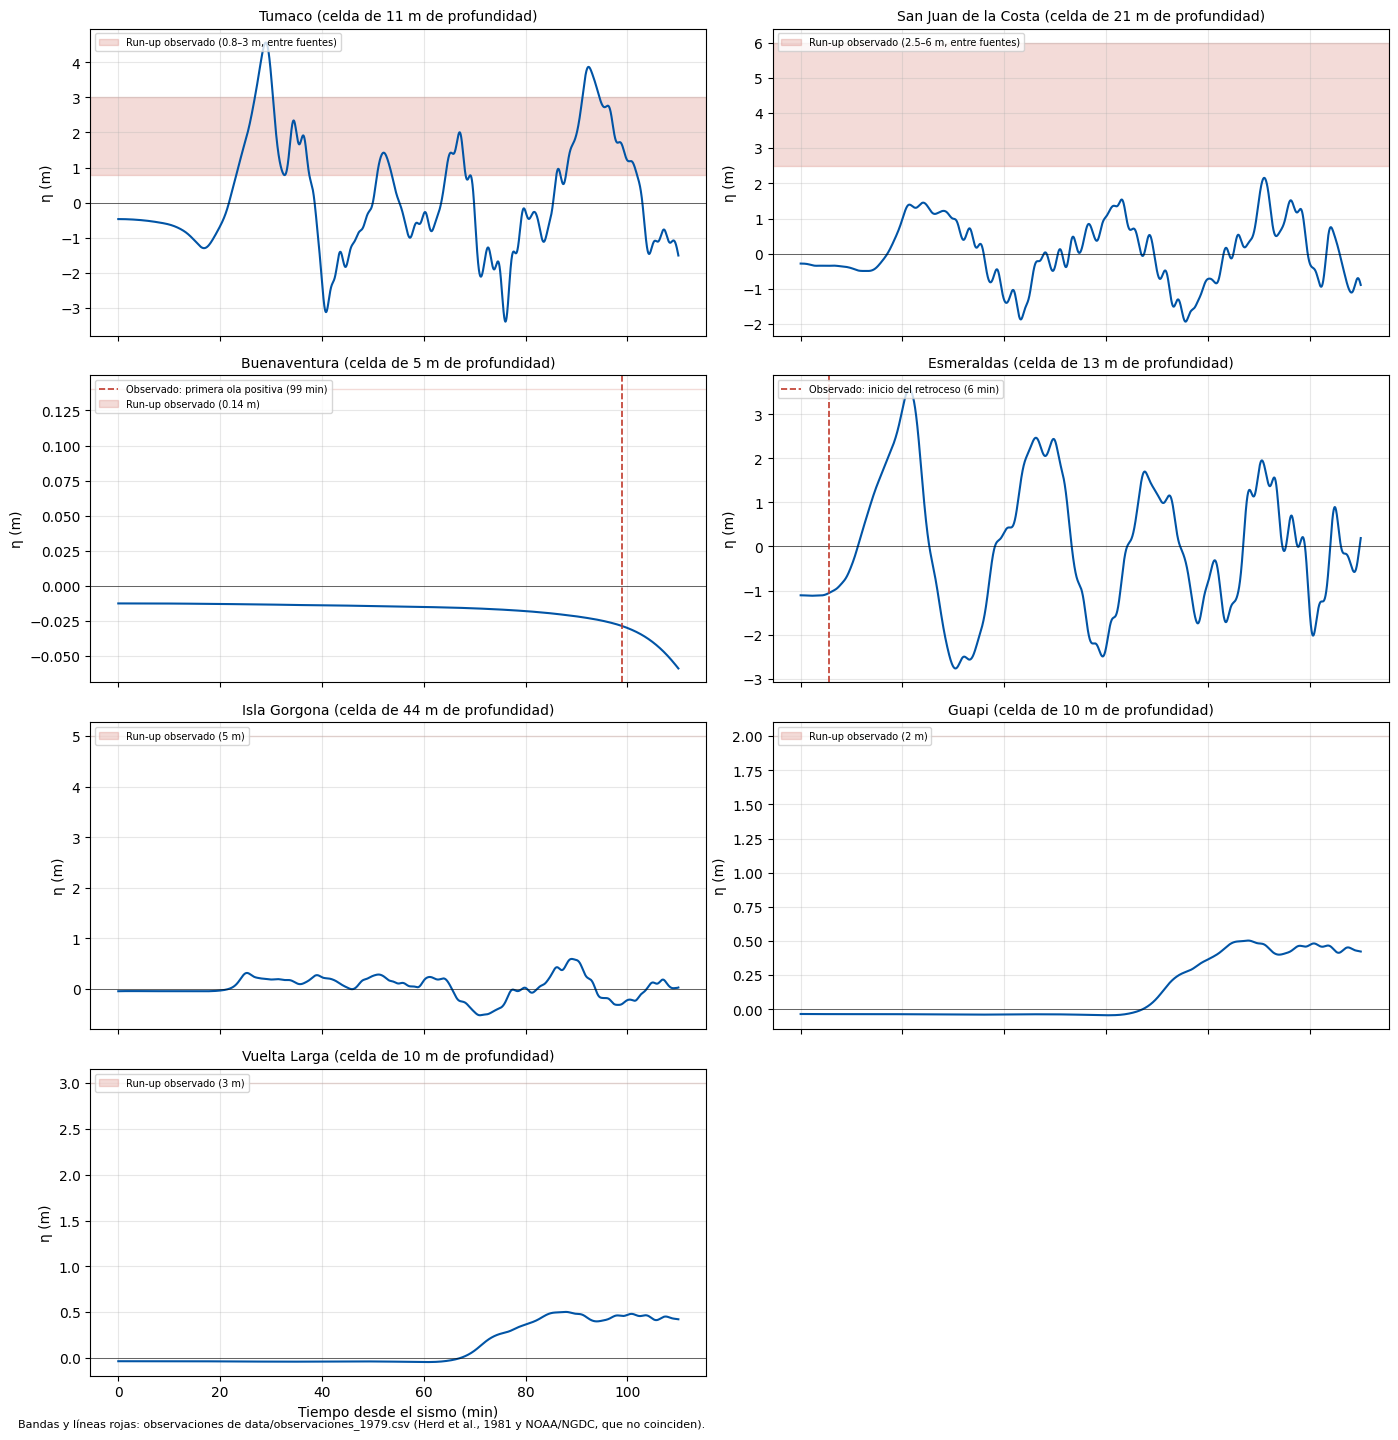

,estacion,H_celda_m,eta_max_m,eta_min_m,t_ascenso_sim_min,t_descenso_sim_min,t_cresta_min,runup_herd_m,runup_noaa_m,runup_min_m,runup_max_m,t_obs_min,t_obs_tipo,t_comparable_sim_min,dif_t_min,razon_vs_min,razon_vs_max
0,Tumaco,10.70,4.56,-3.39,21.93,0.00,28.97,0.8,3.00,0.80,3.00,NaN,NaN,NaN,NaN,5.70,1.52
1,San Juan de la Costa,20.98,2.16,-1.93,17.43,0.00,91.03,2.5,6.00,2.50,6.00,NaN,NaN,NaN,NaN,0.86,0.36
2,Buenaventura,5.05,-0.01,-0.06,NaN,NaN,0.00,NaN,0.14,0.14,0.14,99.0,primera_ola_positiva,NaN,NaN,NaN,NaN
3,Esmeraldas,12.92,3.57,-2.77,11.48,0.00,21.33,NaN,NaN,NaN,NaN,5.5,retroceso,NaN,NaN,NaN,NaN
4,Isla Gorgona,43.85,0.60,-0.52,23.25,66.03,89.05,NaN,5.00,5.00,5.00,NaN,NaN,NaN,NaN,0.12,0.12
5,Guapi,10.43,0.50,-0.04,70.42,NaN,87.87,NaN,2.00,2.00,2.00,NaN,NaN,NaN,NaN,0.25,0.25
6,Vuelta Larga,10.43,0.50,-0.04,70.42,NaN,87.87,NaN,3.00,3.00,3.00,NaN,NaN,NaN,NaN,0.17,0.17


In [5]:
ok = est[est.estado == 'ok'].reset_index(drop=True)
def primer(s, signo):
    """Primer instante (min) en que la serie `s` supera +0,1 m (`signo` > 0) o baja de −0,1 m (`signo` < 0); NaN si nunca ocurre."""
    m = (s > 0.1) if signo > 0 else (s < -0.1)
    return tt[np.argmax(m)] / 60 if m.any() else np.nan
sim = []
for k, r in ok.iterrows():
    s = rec[:, k]
    sim.append(dict(estacion=r.estacion, H_celda_m=r.H_celda_m, eta_max_m=s.max(), eta_min_m=s.min(),
                    t_ascenso_sim_min=primer(s, +1), t_descenso_sim_min=primer(s, -1), t_cresta_min=tt[np.argmax(s)] / 60))
sim = pd.DataFrame(sim).merge(qc[['estacion', 'runup_herd_m', 'runup_noaa_m', 'runup_min_m', 'runup_max_m', 't_obs_min', 't_obs_tipo']], on='estacion')
# El retroceso de Esmeraldas no se compara en tiempo: la fuente es instantánea y η ya es negativo en t = 0
sim['t_comparable_sim_min'] = np.where(sim.t_obs_tipo == 'primera_ola_positiva', sim.t_ascenso_sim_min, np.nan)
sim['dif_t_min'] = (sim.t_comparable_sim_min - sim.t_obs_min).round(1)
# La razón solo tiene sentido donde el modelo produce una ola (η máx. > 0,1 m, el umbral de arribo)
hay_ola = sim.eta_max_m > 0.1
sim['razon_vs_min'] = np.where(hay_ola, sim.eta_max_m / sim.runup_min_m, np.nan).round(2)
sim['razon_vs_max'] = np.where(hay_ola, sim.eta_max_m / sim.runup_max_m, np.nan).round(2)

n = len(sim); nc = 2; nr = int(np.ceil(n / nc))
fig, axs = plt.subplots(nr, nc, figsize=(14, 3.6 * nr), sharex=True, squeeze=False)
for k, (ax, (_, r)) in enumerate(zip(axs.flat, sim.iterrows())):
    ax.plot(tt / 60, rec[:, k], c='#0154a5', lw=1.5); ax.axhline(0, c='k', lw=.4)
    if isinstance(r.t_obs_tipo, str):
        etiqueta = 'primera ola positiva' if r.t_obs_tipo == 'primera_ola_positiva' else 'inicio del retroceso'
        ax.axvline(r.t_obs_min, c='#c0392b', ls='--', lw=1.2, label=f'Observado: {etiqueta} ({r.t_obs_min:.0f} min)')
    if pd.notna(r.runup_min_m):
        ax.axhspan(r.runup_min_m, r.runup_max_m, color='#c0392b', alpha=.18, label=('Run-up observado (' + (f'{r.runup_min_m:g} m' if r.runup_min_m == r.runup_max_m else f'{r.runup_min_m:g}–{r.runup_max_m:g} m, entre fuentes') + ')'))
    ax.set_title(f'{r.estacion} (celda de {r.H_celda_m:.0f} m de profundidad)', fontsize=10); ax.set_ylabel('η (m)'); ax.grid(alpha=.3)
    if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=7, loc='upper left')
for ax in axs.flat[n:]: ax.axis('off')
for ax in axs[-1]: ax.set_xlabel('Tiempo desde el sismo (min)')
fig.text(.01, .005, 'Bandas y líneas rojas: observaciones de data/observaciones_1979.csv (Herd et al., 1981 y NOAA/NGDC, que no coinciden).', fontsize=8)
plt.tight_layout(); plt.savefig(WORK / 'time_series.png', dpi=130, bbox_inches='tight'); plt.show()
sim.round(2)

## 4. Comparación indicativa con las observaciones

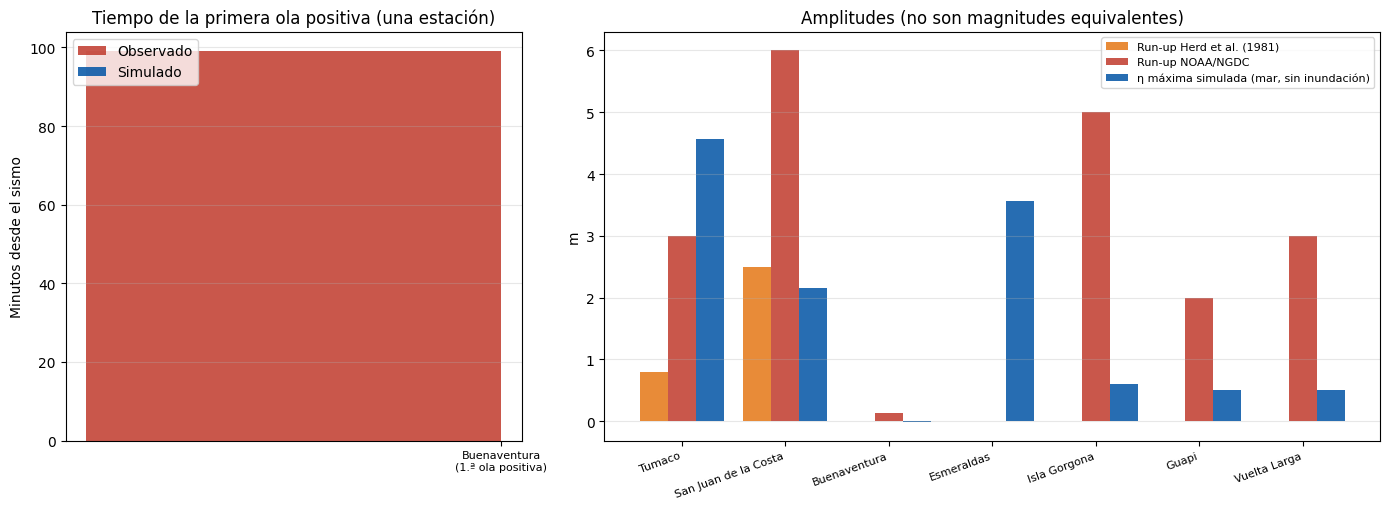

Estaciones comparables: 7 de 12
Excluidas:
 estacion                                                estado
  Limones sin mar de ≥ 10 m a < 10 km (el más cercano, a 15 km)
 Iscuandé sin mar de ≥ 10 m a < 10 km (el más cercano, a 24 km)
El Charco sin mar de ≥ 10 m a < 10 km (el más cercano, a 12 km)
 Timbiquí sin mar de ≥ 10 m a < 10 km (el más cercano, a 14 km)
 El Barro sin mar de ≥ 10 m a < 10 km (el más cercano, a 20 km)

Tiempo en Buenaventura: observado 99 min; el modelo no produce un ascenso > 0,1 m en 110 min (η máx. = -0.01 m en la celda de 5 m)
Esmeraldas: η < −0,1 m desde t = 0 (condición inicial) y primer ascenso a los 11 min; observado: retroceso del mar a los 5–6 min. Coincide el signo del primer movimiento; el tiempo no es comparable (la fuente es instantánea).
η simulada / run-up: entre 0.12 y 5.70 (η sobre el menor y sobre el mayor valor de cada estación)


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.7]})
ax = axs[0]
tobs = sim[sim.t_obs_tipo == 'primera_ola_positiva'].reset_index(drop=True)
xp = np.arange(len(tobs)); w = .38
ax.bar(xp - w / 2, tobs.t_obs_min, w, color='#c0392b', alpha=.85, label='Observado')
ax.bar(xp + w / 2, tobs.t_comparable_sim_min, w, color='#0154a5', alpha=.85, label='Simulado')
ax.set_xticks(xp); ax.set_xticklabels([f'{r.estacion}\n({"1.ª ola positiva" if r.t_obs_tipo == "primera_ola_positiva" else "inicio del retroceso"})' for _, r in tobs.iterrows()], fontsize=8)
for k_, r_ in tobs.iterrows():
    if np.isnan(r_.t_comparable_sim_min):
        ax.annotate('modelo: sin ola > 0,1 m\nen 110 min', (k_ + w / 2, 2), ha='center', fontsize=8, color='#0154a5')
ax.set_ylabel('Minutos desde el sismo'); ax.set_title('Tiempo de la primera ola positiva (una estación)'); ax.legend(); ax.grid(axis='y', alpha=.3)

ax = axs[1]; xp = np.arange(len(sim)); w = .27
ax.bar(xp - w, sim.runup_herd_m, w, label='Run-up Herd et al. (1981)', color='#e67e22', alpha=.9)
ax.bar(xp, sim.runup_noaa_m, w, label='Run-up NOAA/NGDC', color='#c0392b', alpha=.85)
ax.bar(xp + w, sim.eta_max_m, w, label='η máxima simulada (mar, sin inundación)', color='#0154a5', alpha=.85)
ax.set_xticks(xp); ax.set_xticklabels(sim.estacion, rotation=20, ha='right', fontsize=8); ax.set_ylabel('m'); ax.legend(fontsize=8); ax.grid(axis='y', alpha=.3)
ax.set_title('Amplitudes (no son magnitudes equivalentes)')
plt.tight_layout(); plt.savefig(WORK / 'validation.png', dpi=130, bbox_inches='tight'); plt.show()

print(f'Estaciones comparables: {len(sim)} de {len(obs)}')
print('Excluidas:'); print(qc[qc.estado != 'ok'][['estacion', 'estado']].to_string(index=False))
print()
for _, r in tobs.iterrows():
    if np.isnan(r.t_comparable_sim_min):
        print(f'Tiempo en {r.estacion}: observado {r.t_obs_min:.0f} min; el modelo no produce un ascenso > 0,1 m en {tt[-1]/60:.0f} min (η máx. = {r.eta_max_m:.2f} m en la celda de {r.H_celda_m:.0f} m)')
    else:
        print(f'Tiempo en {r.estacion}: simulado {r.t_comparable_sim_min:.0f} min, observado {r.t_obs_min:.0f} min ({r.dif_t_min:+.0f} min)')
esm = sim[sim.t_obs_tipo == 'retroceso']
for _, r in esm.iterrows():
    print(f'{r.estacion}: η < −0,1 m desde t = 0 (condición inicial) y primer ascenso a los {r.t_ascenso_sim_min:.0f} min; observado: retroceso del mar a los 5–6 min. '
          'Coincide el signo del primer movimiento; el tiempo no es comparable (la fuente es instantánea).')
cmp_ = sim.dropna(subset=['runup_min_m'])
print(f'η simulada / run-up: entre {cmp_.razon_vs_max.min():.2f} y {cmp_.razon_vs_min.max():.2f} (η sobre el menor y sobre el mayor valor de cada estación)')

### Contraste con resultados publicados

Dos trabajos de la literatura simularon el escenario de 1979 en Tumaco con **modelos no lineales con cálculo de inundación** (Ávila-Guzmán et al. usan TUNAMI-N2) y distribuciones
de deslizamiento de Poveda y Pulido (2019). Se citan aquí **como referencia de orden de magnitud**; su fuente, su malla y sus definiciones difieren de las de este cuaderno.

In [7]:
tum = sim.estacion == "Tumaco"
pub = pd.DataFrame([
    ['Altura máxima del tsunami, isla de Tumaco, escenario 1979 (modelo de déficit de deslizamiento)', '2,30 m', 'Escobar et al. (2020), tabla 3'],
    ['Altura máxima del tsunami, isla de Tumaco, escenario 1979 (modelo de banda ancha)', '1,88 m', 'Escobar et al. (2020), tabla 3'],
    ['Llegada de la primera ola a Tumaco', '22 min', 'Ávila-Guzmán et al. (2026)'],
    ['Run-up observado en Tumaco: Herd et al. (1981) / NOAA/NGDC', '0,8 m / 3 m', 'Herd et al. (1981), p. 442; registro NOAA 9742'],
    ['Este cuaderno: η máxima en celdas de mar de 10-25 m, Tumaco', f'{sim.eta_max_m[tum].min():.1f}-{sim.eta_max_m[tum].max():.1f} m', 'LSWE lineal, 450 m'],
    ['Este cuaderno: primer ascenso > 0,1 m en Tumaco', f'{sim.t_ascenso_sim_min[tum].min():.0f} min', 'LSWE lineal, 450 m']],
    columns=['Magnitud', 'Valor', 'Fuente'])
pub

,Magnitud,Valor,Fuente
0,"Altura máxima del tsunami, isla de Tumaco, esc...","2,30 m","Escobar et al. (2020), tabla 3"
1,"Altura máxima del tsunami, isla de Tumaco, esc...","1,88 m","Escobar et al. (2020), tabla 3"
2,Llegada de la primera ola a Tumaco,22 min,Ávila-Guzmán et al. (2026)
3,Run-up observado en Tumaco: Herd et al. (1981)...,"0,8 m / 3 m","Herd et al. (1981), p. 442; registro NOAA 9742"
4,Este cuaderno: η máxima en celdas de mar de 10...,4.6-4.6 m,"LSWE lineal, 450 m"
5,"Este cuaderno: primer ascenso > 0,1 m en Tumaco",22 min,"LSWE lineal, 450 m"


## 5. Sensibilidad (resumen del cuaderno 2)

In [8]:
sp = OUT / 'sensibilidad.csv'
if sp.exists():
    sens = pd.read_csv(sp, index_col=0)
    cols = [c for c in sens.columns if 'η máx' in c]
    display(sens[cols].describe().loc[['min', 'max']].T.round(2).rename(columns={'min': 'mínimo', 'max': 'máximo'}))
    display(sens[[c for c in sens.columns if 'arribo' in c]].describe().loc[['min', 'max']].T.round(1).rename(columns={'min': 'mínimo', 'max': 'máximo'}))
else:
    print('Ejecute la sección 6 del cuaderno 2 para generar output/sensibilidad.csv')

,mínimo,máximo
Tumaco η máx (m),2.31,4.61
San Juan de la Costa η máx (m),1.88,3.77
Buenaventura η máx (m),-0.01,-0.01
Esmeraldas η máx (m),1.49,4.80
Isla Gorgona η máx (m),0.26,0.60
Guapi η máx (m),0.35,0.61
Vuelta Larga η máx (m),0.34,0.59


,mínimo,máximo
Tumaco arribo (min),18.9,24.7
San Juan de la Costa arribo (min),14.7,20.6
Buenaventura arribo (min),0.0,0.0
Esmeraldas arribo (min),4.2,13.7
Isla Gorgona arribo (min),21.2,26.5
Guapi arribo (min),68.7,75.3
Vuelta Larga arribo (min),68.1,74.6


## 6. Animación de la propagación

Mapa con el **oeste a la izquierda y el norte arriba**; la estrella marca el epicentro y la falla se muestra con su proyección. η en metros (|η| < 0,1 m se deja transparente).

In [9]:
cf_t = None
fig, ax = plt.subplots(figsize=(8.2, 8))
fondo(ax)
ax.contour(np.linspace(ext[0], ext[1], nx), np.linspace(ext[3], ext[2], ny), H, levels=[200, 1000, 3000], colors='#8c99a6', linewidths=.4)
costa(ax)
agua = ax.imshow(np.full(H.shape, np.nan), cmap='RdBu_r', vmin=-3, vmax=3, extent=ext, alpha=.9)
plt.colorbar(agua, ax=ax, shrink=.7, label='η (m)')
ax.plot(ex / 1e3, ey / 1e3, '*', c='red', mec='k', ms=18, zorder=10, label='Epicentro 1979')
for nombre, (lon, lat) in {'Tumaco': (-78.76, 1.82), 'Esmeraldas': (-79.65, 0.97), 'Buenaventura': (-77.02, 3.88)}.items():
    x, y = TR.transform(lon, lat); ax.plot(x / 1e3, y / 1e3, 'ko', ms=4, zorder=9)
    ax.annotate(nombre, (x / 1e3, y / 1e3), textcoords='offset points', xytext=(5, 4), fontsize=8)
ax.legend(loc='upper left'); ejes_lonlat(ax)
ax.set_xlim(ext[0] + 5, ext[1] - 5); ax.set_ylim(ext[2] + 5, ext[3] - 5)
titulo = ax.set_title('')

def cuadro(k):
    """Actualiza el cuadro `k` de la animación: la elevación del agua (m) donde supera 0,1 m en mar de al menos 10 m de profundidad. Devuelve los artistas modificados."""
    e = snaps[k].astype('float32'); agua.set_array(np.where((np.abs(e) > 0.1) & (H >= 10), e, np.nan))
    titulo.set_text(f't = {snap_t[k]/60:.0f} min — Tsunami de Tumaco 1979 (LSWE)')
    return [agua, titulo]

anim = FuncAnimation(fig, cuadro, frames=len(snap_t), interval=250, blit=False)
gif = WORK / 'tsunami_propagation.gif'
anim.save(str(gif), writer=PillowWriter(fps=4), dpi=80)
plt.close(fig)
print(f'✓ Animación: {len(snap_t)} cuadros, t = 0–{snap_t[-1]/60:.0f} min, {gif.stat().st_size/1e6:.1f} MB')

✓ Animación: 28 cuadros, t = 0–108 min, 1.7 MB


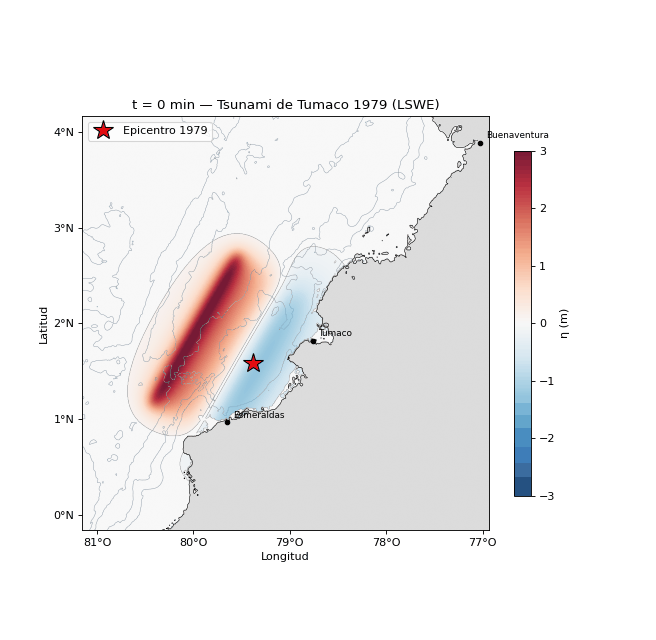

In [10]:
from IPython.display import Image, display
display(Image(str(gif)))

## 7. Resumen

In [11]:
print('=' * 62); print('RESUMEN — TSUNAMI DE TUMACO 1979 (versión 2)'); print('=' * 62)
print(f'  Modelo:              LSWE, malla escalonada, {dx:.0f} m, dt = {dt:.0f} s')
print(f'  Fuente:              Okada (1985), Mw {8.3}, deslizamiento uniforme {float(R["slip"]):.1f} m (geometría supuesta)')
print(f'  η máx. (≥ 10 m prof.): {maxeta[H>=10].max():.2f} m | plataforma 10–200 m: {maxeta[zona].max():.2f} m')
print(f'  Estaciones:          {len(sim)} comparables de {len(obs)} (resto excluido, ver sección 4)')
for _, r in tobs.iterrows():
    print(f'  Tiempo {r.estacion}:'.ljust(23) + ('el modelo no produce una ola > 0,1 m' if np.isnan(r.t_comparable_sim_min) else f'sim − obs = {r.dif_t_min:+.0f} min') + f' (observado: primera ola positiva a los {r.t_obs_min:.0f} min)')
print('  Esmeraldas:          el signo del primer movimiento (descenso) coincide con Herd; el tiempo no es comparable')
print(f'  η sim / run-up obs:  {cmp_.razon_vs_max.min():.2f} a {cmp_.razon_vs_min.max():.2f} (Herd y NOAA no coinciden entre sí)')
for f in ['max_eta_map.png', 'time_series.png', 'validation.png', 'tsunami_propagation.gif', 'fuente_okada.png']:
    p = WORK / f; print(f'  {"✓" if p.exists() else "✗"} {f}')

RESUMEN — TSUNAMI DE TUMACO 1979 (versión 2)
  Modelo:              LSWE, malla escalonada, 450 m, dt = 1 s
  Fuente:              Okada (1985), Mw 8.3, deslizamiento uniforme 7.4 m (geometría supuesta)
  η máx. (≥ 10 m prof.): 8.80 m | plataforma 10–200 m: 8.80 m
  Estaciones:          7 comparables de 12 (resto excluido, ver sección 4)
  Tiempo Buenaventura: el modelo no produce una ola > 0,1 m (observado: primera ola positiva a los 99 min)
  Esmeraldas:          el signo del primer movimiento (descenso) coincide con Herd; el tiempo no es comparable
  η sim / run-up obs:  0.12 a 5.70 (Herd y NOAA no coinciden entre sí)
  ✓ max_eta_map.png
  ✓ time_series.png
  ✓ validation.png
  ✓ tsunami_propagation.gif
  ✓ fuente_okada.png
